In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import time
import random
import plotly.express as px
import seaborn as sns
import scipy.special as scispe
import seaborn as sns
import plotly.figure_factory as ff
import pickle
from IPython.display import clear_output
from plotly.subplots import make_subplots
import plotly.graph_objects as go

from LIBS.network1_library import from_edgelist_to_amatrix
from LIBS.embedding_library_martin import coalescent_embedding_2D
from LIBS.after_embedding_library import create_nan, hyp_dist, normalize_radius
from LIBS.hyperboloid_embedding_library import plot_Pdisk_embedding
from LIBS.kNHD_score_library import from_embedding_to_idxKNNmatrix,from_KNNmatrix_to_scores, two_nets_kNHD_score, two_nets_kNHD_score_2, coalescent_embedding_2D_fc
from LIBS.perturbatations import perturbation_disconnection_NT
from LIBS.networks_class_definition_1 import networks
import LIBS.networks_class_definition_1 as ncd
from LIBS.utils import * 

In [2]:
model = "WattsStrogatz"
N = 50
kl = 20 #k lattice
pr = 0.1 #p rewiring

G = nx.watts_strogatz_graph(N,kl,pr)

degrees = np.array(list(nx.degree(G)))[:,1]

In [3]:
# Embedding parameters 
embedding_parameters_dict = {
'preweight':True, 
'laplacian':False, 
'dim_red_method':'ISOMAP', 
'eigen_solver':'dense', 
'n_neighbors':'auto', 
'equi_adj':True, 
'eta_r':8,
'beta_r':0.8,
'order_r':'auto',
'weight_r':None,
'radius_def':True,
'order_sign':1,
'max_r_margin':1e-5,
}
embedding_parameters = np.array(list(embedding_parameters_dict.values()))

output_folder = 'OUTPUT-MEDIA-test-k/output-WS-testk/'
media_folder = 'OUTPUT-MEDIA-test-k/media-WS-testk/'

In [4]:
# perturbation magnitude 20-40-60-80/100
mag_arr = np.array([20/100, 40/100, 60/100, 80/100])
alpha_dict_WS = {mag_arr[0]:1/1000, mag_arr[1]:1/20000, mag_arr[2]:1/20000, mag_arr[3]:1/1000}

mag = mag_arr[0]
print(mag)

"""
#### Determine number of perturbations to apply
# determine number of perturbations to apply
k_avg = np.average(degrees).astype('int') # take one of the graphs to determine k_avg, since it is approximately the same for all the graphs
print('k average =',k_avg)
km = np.round(k_avg*mag).astype('int')
a_p = scispe.binom(k_avg, km) # mean field estimate of the number of possible perturbations per node
print('a_p =',a_p)

alpha = alpha_dict_WS[mag] # we sample the order of a fraction alpha of all the possible permutations
n_p = round(a_p*alpha*N)
print('n_p =',n_p)

n_t = n_p #total number of perturbations
print('n_t =',n_t)
"""

0.2


"\n#### Determine number of perturbations to apply\n# determine number of perturbations to apply\nk_avg = np.average(degrees).astype('int') # take one of the graphs to determine k_avg, since it is approximately the same for all the graphs\nprint('k average =',k_avg)\nkm = np.round(k_avg*mag).astype('int')\na_p = scispe.binom(k_avg, km) # mean field estimate of the number of possible perturbations per node\nprint('a_p =',a_p)\n\nalpha = alpha_dict_WS[mag] # we sample the order of a fraction alpha of all the possible permutations\nn_p = round(a_p*alpha*N)\nprint('n_p =',n_p)\n\nn_t = n_p #total number of perturbations\nprint('n_t =',n_t)\n"

#### Compute the score for 1 node of the same graph and perturbation, varying the parameter k from 0 to N

In [5]:
t = 10

G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[t])

k_arr = np.arange(1,N,5)

NHD_score_GGp = np.zeros((len(k_arr),N))

for i,k in enumerate(k_arr):

    NHD_score_GGp[i,:] = two_nets_kNHD_score(G,G_p,k,*embedding_parameters)

Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-Perturbati

Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)


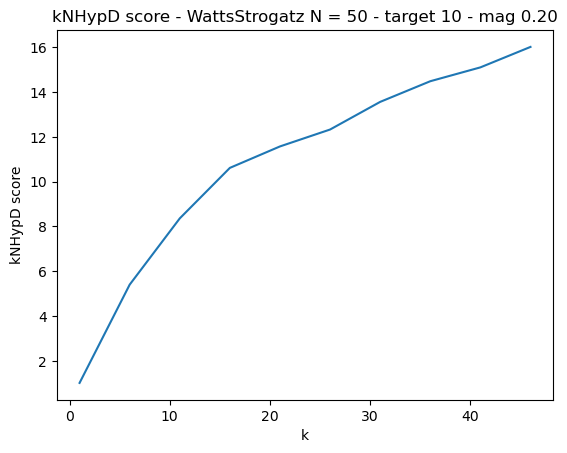

In [6]:
# PLOT

plt.figure()
plt.plot(k_arr,NHD_score_GGp[:,t])
plt.xlabel('k')
plt.ylabel('kNHypD score')
plt.title('kNHypD score - %s N = %i - target %i - mag %.2f'%(model, N, t, mag))
plt.savefig(media_folder+"score-vs-k-%sN%i"%(model,N))
plt.show()

In [7]:
t = 10

G_p, nodes_p_dict = perturbation_disconnection_NT(G,mag,1,target=[t])

k_arr = np.arange(1,N,5)

NHD_score_2_GGp = np.zeros((len(k_arr),N))

for i,k in enumerate(k_arr):

    NHD_score_2_GGp[i,:] = two_nets_kNHD_score_2(G,G_p,k,*embedding_parameters)

Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)
/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/networks_class_definition_1.py:967: FutureWarning: adjacency_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  M = nx.adjacency_matrix(G).toarray()
/Users/alice.longhena/Desktop/GitHub/kNHD-score-Perturbati

Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done
Initialisation of the class done


/Users/alice.longhena/Desktop/GitHub/kNHD-score-PerturbationDetection/LIBS/kNHD_score_library.py:46: RuntimeWarning: invalid value encountered in arccosh
  dist_arr = np.arccosh(cosh_d)


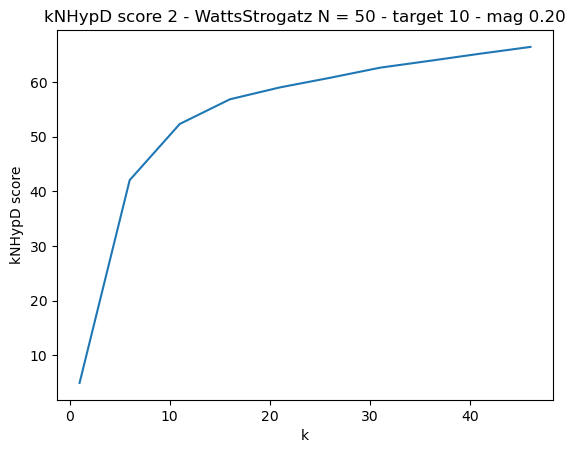

In [8]:
plt.figure()
plt.plot(k_arr,NHD_score_2_GGp[:,t])
plt.xlabel('k')
plt.ylabel('kNHypD score')
plt.title('kNHypD score 2 - %s N = %i - target %i - mag %.2f'%(model, N, t, mag))
plt.savefig(media_folder+"score_2-vs-k-%sN%i"%(model,N))
plt.show()